In [5]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
USE_DURATION = True
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

In [6]:
df_raw = pd.read_csv(r"D:\tasks\bank.csv")
print(df_raw.shape)
df_raw.head()

(8912, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [7]:
df_raw.info()
print(df_raw.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   str    
 2   marital    8743 non-null   str    
 3   education  8885 non-null   str    
 4   default    8908 non-null   str    
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   str    
 7   loan       8882 non-null   str    
 8   contact    8881 non-null   str    
 9   day        8893 non-null   float64
 10  month      8884 non-null   str    
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   str    
 16  deposit    8903 non-null   str    
dtypes: float64(6), int64(1), str(10)
memory usage: 1.2 MB
0


9


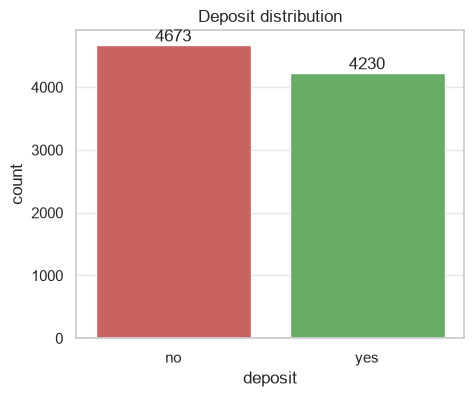

deposit
no     52.5
yes    47.5
Name: proportion, dtype: float64


In [8]:
print(df_raw["deposit"].isnull().sum())

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_raw, x="deposit", palette=["#d9534f", "#5cb85c"], order=["no", "yes"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),ha="center", va="bottom")
plt.title("Deposit distribution")
plt.show()

print((df_raw["deposit"].value_counts(normalize=True) * 100).round(1))

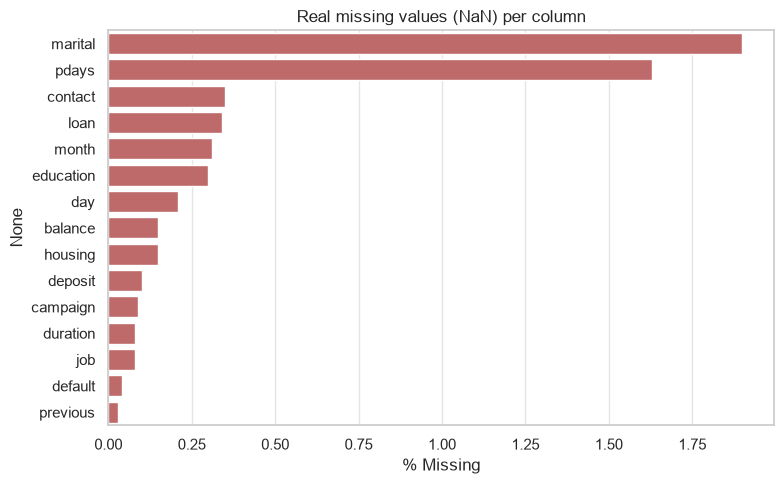

,missing %,count
marital,1.90,169
pdays,1.63,145
contact,0.35,31
loan,0.34,30
month,0.31,28
education,0.30,27
day,0.21,19
balance,0.15,13
housing,0.15,13
deposit,0.10,9


In [9]:
miss = df_raw.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_pct = (miss / len(df_raw) * 100).round(2)

plt.figure(figsize=(8, 5))
sns.barplot(x=miss_pct.values, y=miss_pct.index, color="indianred")
plt.xlabel("% Missing")
plt.title("Real missing values (NaN) per column")
plt.tight_layout()
plt.show()

miss_pct.to_frame("missing %").assign(count=miss)

In [10]:
for c in ["job", "education", "contact", "poutcome"]:
    n = (df_raw[c].str.lower() == "unknown").sum()
    print(f"{c:<10} 'unknown' = {n:>5}  ({n / len(df_raw) * 100:.1f}%)")

print("\npdays == -1 :", (df_raw["pdays"] == -1).sum(), f"({(df_raw['pdays'] == -1).mean() * 100:.1f}%)")

job        'unknown' =    57  (0.6%)
education  'unknown' =   389  (4.4%)
contact    'unknown' =  1876  (21.1%)
poutcome   'unknown' =  6638  (74.5%)

pdays == -1 : 6491 (72.8%)


In [11]:
df = df_raw.copy()

for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].str.strip().str.lower()

df = df[df["deposit"].notna()].copy()
df["deposit"] = (df["deposit"] == "yes").astype(int)

for c in ["default", "housing", "loan"]:
    df[c] = df[c].map({"yes": 1, "no": 0})

df["prev_contacted"] = (df["poutcome"] != "unknown").astype(int)
df["pdays"] = df["pdays"].replace(-1, 0)

for c in ["duration", "campaign", "previous", "pdays"]:
    df[c] = np.log1p(df[c])
df["balance"] = np.sign(df["balance"]) * np.log1p(df["balance"].abs())
if not USE_DURATION:
    df = df.drop(columns="duration")

df = df.reset_index(drop=True)
print(df.shape)
left = df.isnull().sum()
left[left > 0]

(8903, 18)


job            7
marital      160
education     27
default        4
balance       13
housing       13
loan          30
contact       31
day           19
month         28
duration       7
campaign       8
pdays        136
previous       3
dtype: int64

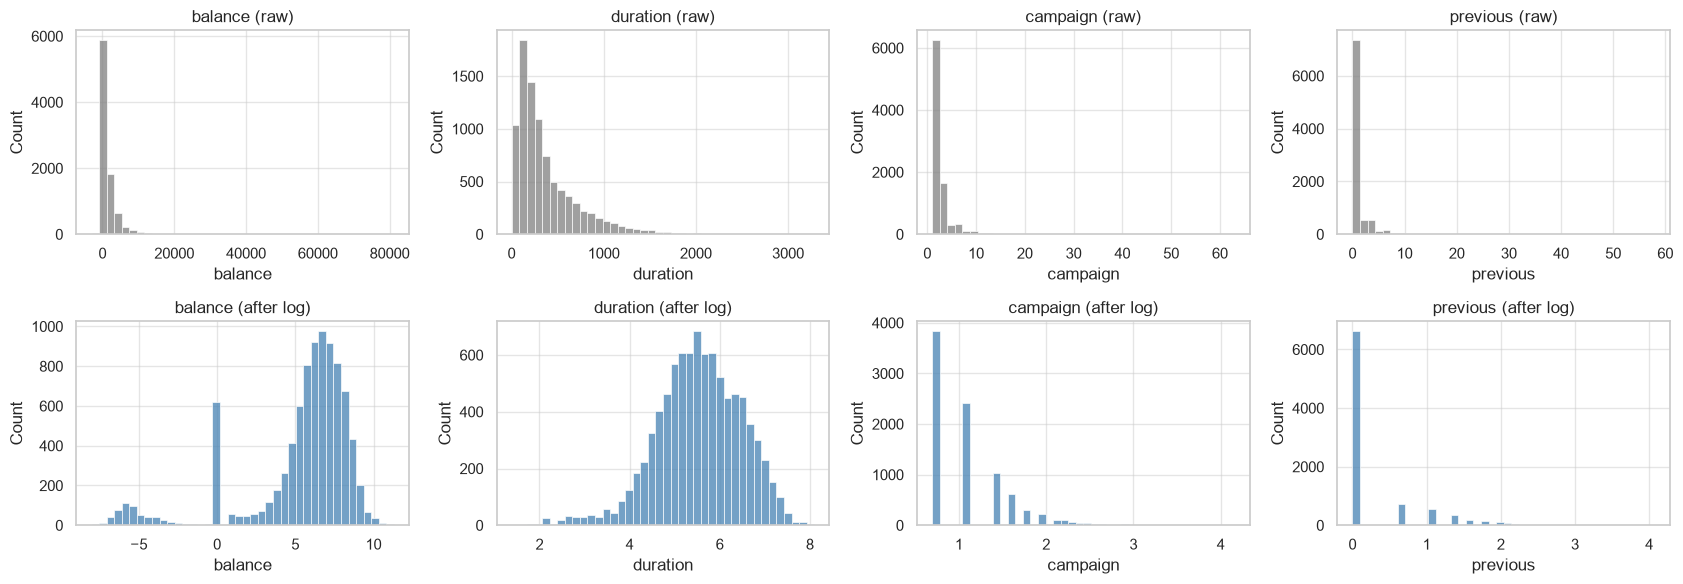

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6))
for j, c in enumerate(["balance", "duration", "campaign", "previous"]):
    sns.histplot(df_raw[c].dropna(), bins=40, ax=axes[0, j], color="gray")
    axes[0, j].set_title(f"{c} (raw)")
    sns.histplot(df[c].dropna(), bins=40, ax=axes[1, j], color="steelblue") if c in df.columns else None
    axes[1, j].set_title(f"{c} (after log)")
plt.tight_layout()
plt.show()

In [13]:
X = df.drop(columns="deposit")
y = df["deposit"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (7122, 17) | Test: (1781, 17)
0.475 0.475


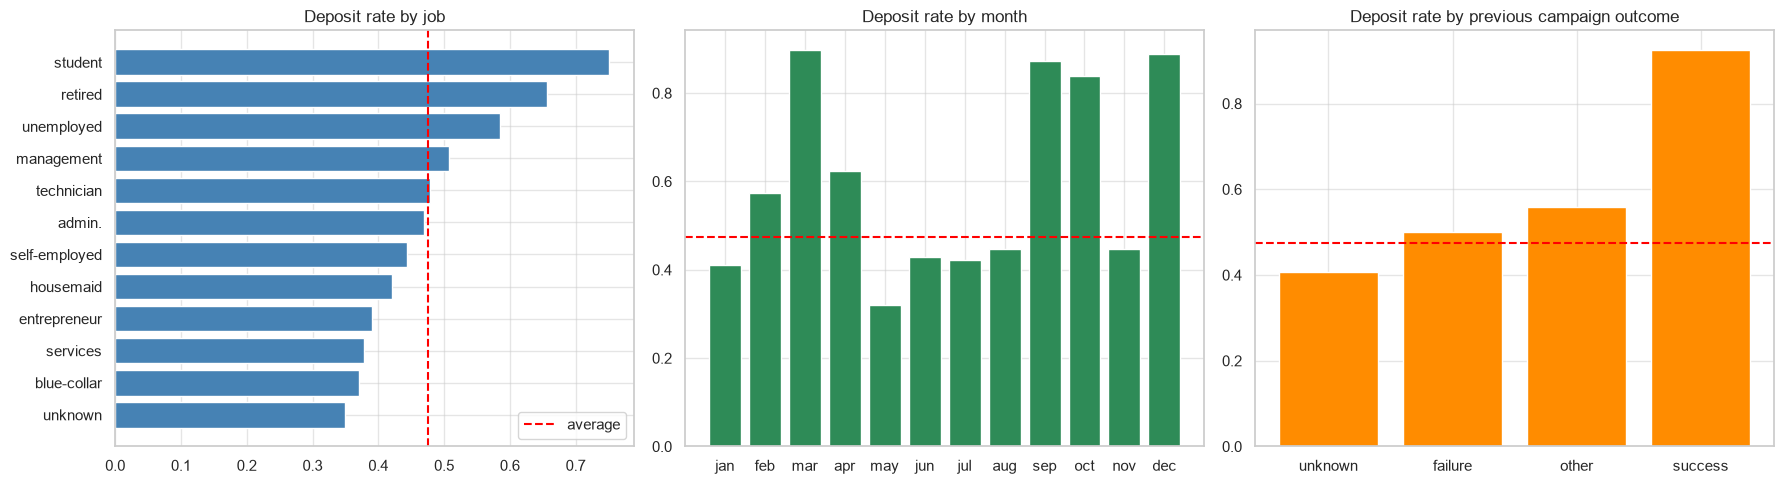

In [14]:
train_df = X_train.copy()
train_df["deposit"] = y_train

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

rate = train_df.groupby("job")["deposit"].mean().sort_values()
axes[0].barh(rate.index, rate.values, color="steelblue")
axes[0].axvline(train_df["deposit"].mean(), color="red", ls="--", label="average")
axes[0].set_title("Deposit rate by job"); axes[0].legend()

rate = train_df.groupby("month")["deposit"].mean().reindex(MONTH_ORDER)
axes[1].bar(rate.index, rate.values, color="seagreen")
axes[1].axhline(train_df["deposit"].mean(), color="red", ls="--")
axes[1].set_title("Deposit rate by month")

rate = train_df.groupby("poutcome")["deposit"].mean().sort_values()
axes[2].bar(rate.index, rate.values, color="darkorange")
axes[2].axhline(train_df["deposit"].mean(), color="red", ls="--")
axes[2].set_title("Deposit rate by previous campaign outcome")

plt.tight_layout()
plt.show()

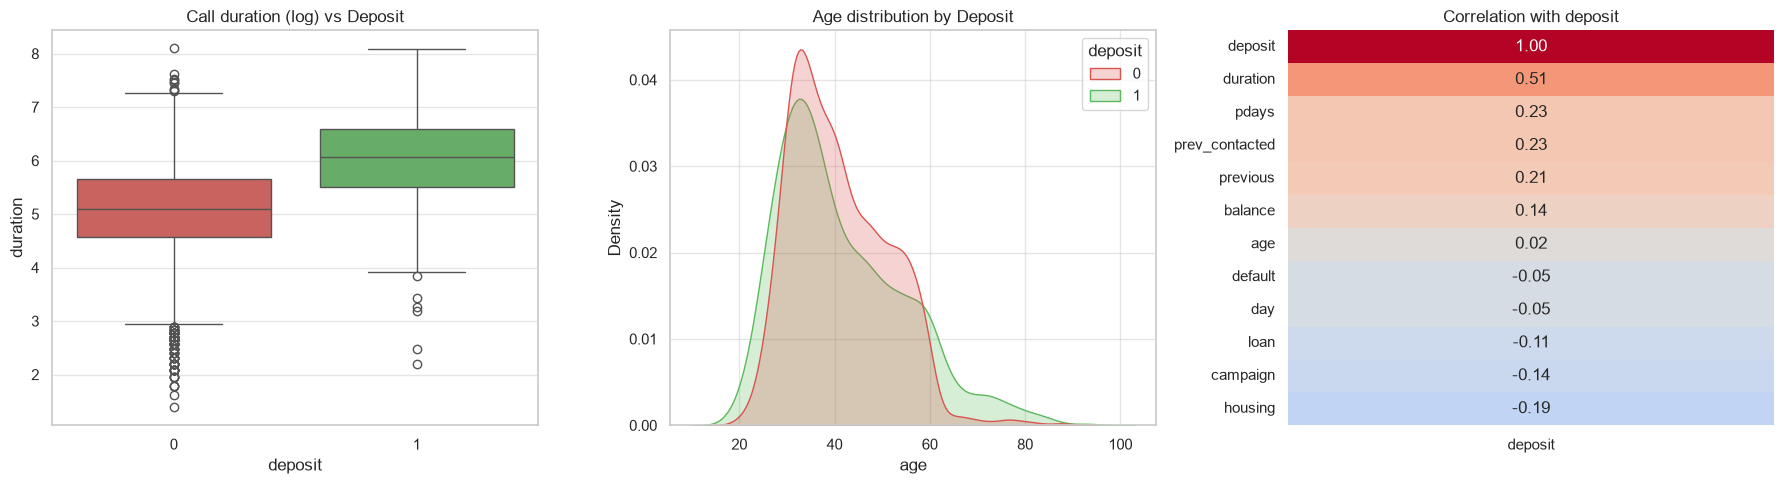

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=train_df, x="deposit", y="duration", ax=axes[0], palette=["#d9534f", "#5cb85c"])
axes[0].set_title("Call duration (log) vs Deposit")

sns.kdeplot(data=train_df, x="age", hue="deposit", common_norm=False, fill=True, ax=axes[1],
            palette=["#d9534f", "#5cb85c"])
axes[1].set_title("Age distribution by Deposit")

num_in_df = [c for c in train_df.select_dtypes("number").columns]
corr = train_df[num_in_df].corr()
sns.heatmap(corr[["deposit"]].sort_values("deposit", ascending=False), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[2], cbar=False)
axes[2].set_title("Correlation with deposit")

plt.tight_layout()
plt.show()

In [16]:
def make_preprocessor(X):
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = X.select_dtypes(exclude="number").columns.tolist()
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler",  StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

preprocessor = make_preprocessor(X_train)

Xt = clone(preprocessor).fit_transform(X_train)
print(Xt.shape)
print(np.isnan(Xt).sum())

(7122, 49)
0


In [17]:
models = {
    "Logistic Regression":  LogisticRegression(max_iter=2000),
    "KNN":                  KNeighborsClassifier(n_neighbors=15),
    "SVC (RBF)":            SVC(C=1.0),
    "Naive Bayes":          GaussianNB(),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                          max_iter=500, random_state=RANDOM_STATE),
    "Decision Tree":        DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost":             AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                                       subsample=0.8, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
if XGBClassifier is not None:
    models["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                      colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
if LGBMClassifier is not None:
    models["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8,
                                        colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted, scores, preds = [], {}, {}, {}

for name, model in models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])

    cv_acc = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="accuracy", n_jobs=1).mean()

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)

    fitted[name], scores[name], preds[name] = pipe, score, pred
    rows.append({
        "Model": name,
        "CV Accuracy": cv_acc,
        "Test Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "ROC-AUC":   roc_auc_score(y_test, score),
        "Time (s)":  time.time() - t0,
    })
    print(f"✔ {name:<22} Acc = {rows[-1]['Test Accuracy']:.4f}   AUC = {rows[-1]['ROC-AUC']:.4f}   ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
results.round(4)

✔ Logistic Regression    Acc = 0.8237   AUC = 0.8949   (1.2s)
✔ KNN                    Acc = 0.8119   AUC = 0.8769   (1.1s)
✔ SVC (RBF)              Acc = 0.8467   AUC = 0.9081   (16.9s)
✔ Naive Bayes            Acc = 0.6816   AUC = 0.7696   (0.6s)
✔ Neural Network (MLP)   Acc = 0.8405   AUC = 0.9077   (14.8s)
✔ Decision Tree          Acc = 0.8113   AUC = 0.8586   (0.8s)
✔ Random Forest          Acc = 0.8506   AUC = 0.9099   (8.9s)
✔ Extra Trees            Acc = 0.8209   AUC = 0.8910   (7.5s)
✔ AdaBoost               Acc = 0.8214   AUC = 0.8890   (17.8s)
✔ Gradient Boosting      Acc = 0.8490   AUC = 0.9167   (26.3s)
✔ HistGradientBoosting   Acc = 0.8551   AUC = 0.9204   (7.4s)
✔ XGBoost                Acc = 0.8557   AUC = 0.9175   (4.7s)
✔ LightGBM               Acc = 0.8535   AUC = 0.9187   (3.0s)


,Model,CV Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC,Time (s)
0,HistGradientBoosting,0.8613,0.8551,0.8210,0.8889,0.8536,0.9204,7.3633
1,LightGBM,0.8595,0.8535,0.8183,0.8889,0.8521,0.9187,3.0347
2,XGBoost,0.8597,0.8557,0.8205,0.8913,0.8544,0.9175,4.7093
3,Gradient Boosting,0.8566,0.8490,0.8195,0.8747,0.8462,0.9167,26.2674
4,Random Forest,0.8522,0.8506,0.8125,0.8913,0.8501,0.9099,8.8609
5,SVC (RBF),0.8463,0.8467,0.8077,0.8889,0.8464,0.9081,16.8710
6,Neural Network (MLP),0.8467,0.8405,0.8122,0.8641,0.8373,0.9077,14.7875
7,Logistic Regression,0.8241,0.8237,0.7995,0.8392,0.8189,0.8949,1.1873
8,Extra Trees,0.8304,0.8209,0.8046,0.8227,0.8136,0.8910,7.4572
9,AdaBoost,0.8192,0.8214,0.8128,0.8109,0.8118,0.8890,17.8404


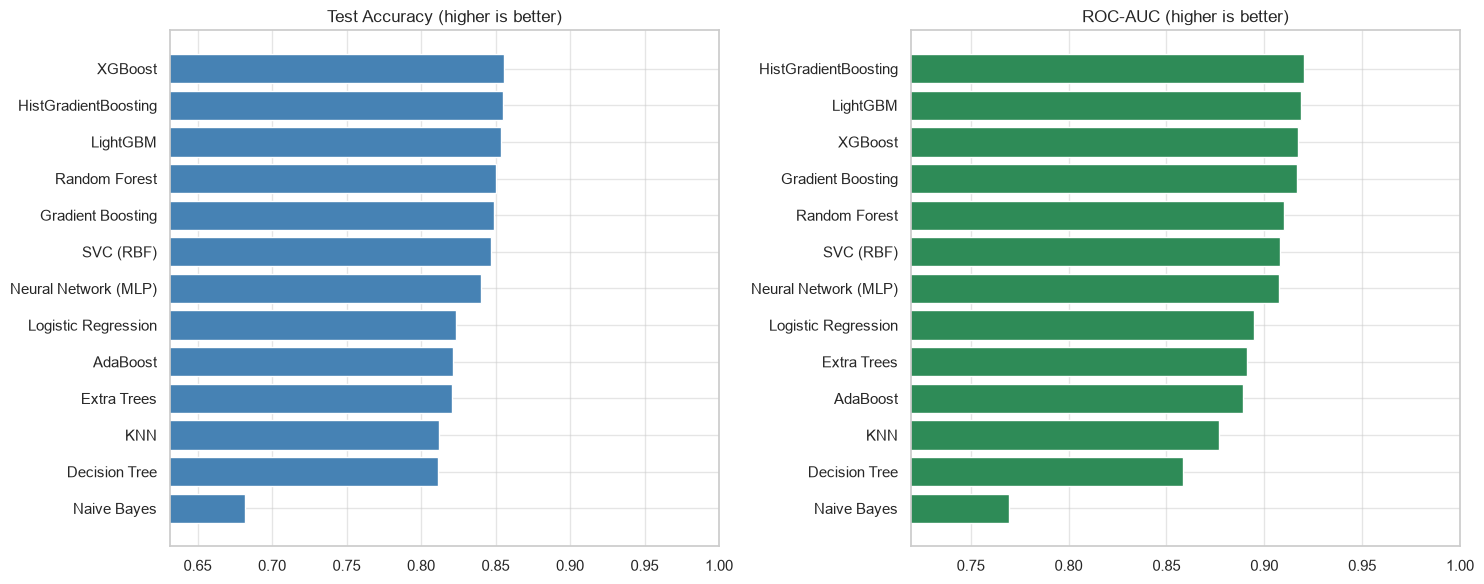

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

order = results.sort_values("Test Accuracy")
axes[0].barh(order["Model"], order["Test Accuracy"], color="steelblue")
axes[0].set_xlim(max(0, order["Test Accuracy"].min() - 0.05), 1)
axes[0].set_title("Test Accuracy (higher is better)")

order = results.sort_values("ROC-AUC")
axes[1].barh(order["Model"], order["ROC-AUC"], color="seagreen")
axes[1].set_xlim(max(0.5, order["ROC-AUC"].min() - 0.05), 1)
axes[1].set_title("ROC-AUC (higher is better)")

plt.tight_layout()
plt.show()

In [19]:
best_name = results.loc[0, "Model"]
print(best_name)
print(results.loc[0].drop("Model").astype(float).round(4).to_string())

HistGradientBoosting
CV Accuracy      0.8613
Test Accuracy    0.8551
Precision        0.8210
Recall           0.8889
F1               0.8536
ROC-AUC          0.9204
Time (s)         7.3633


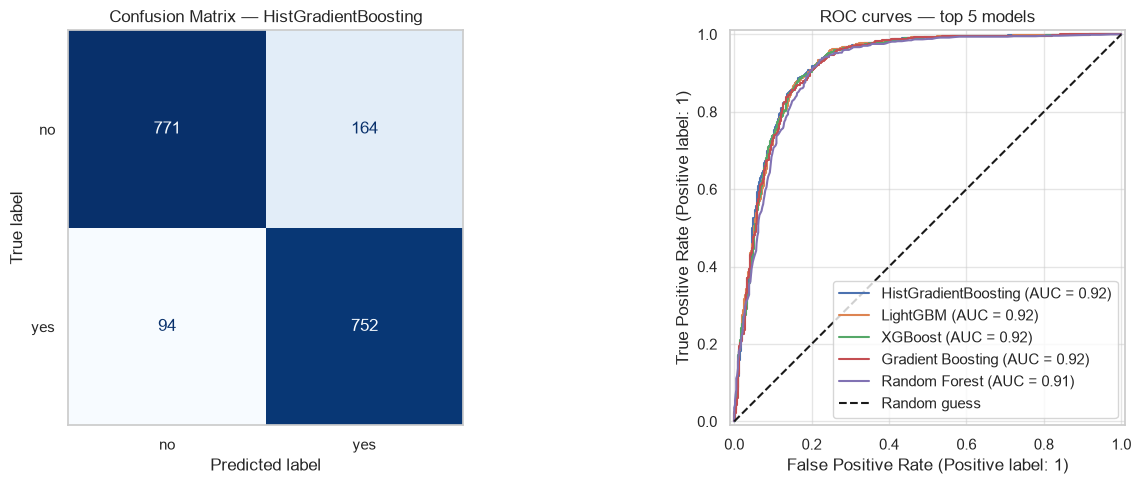

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(y_test, preds[best_name], display_labels=["no", "yes"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion Matrix — {best_name}")
axes[0].grid(False)

for name in results["Model"].head(5):
    RocCurveDisplay.from_predictions(y_test, scores[name], name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC curves — top 5 models")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

LightGBM


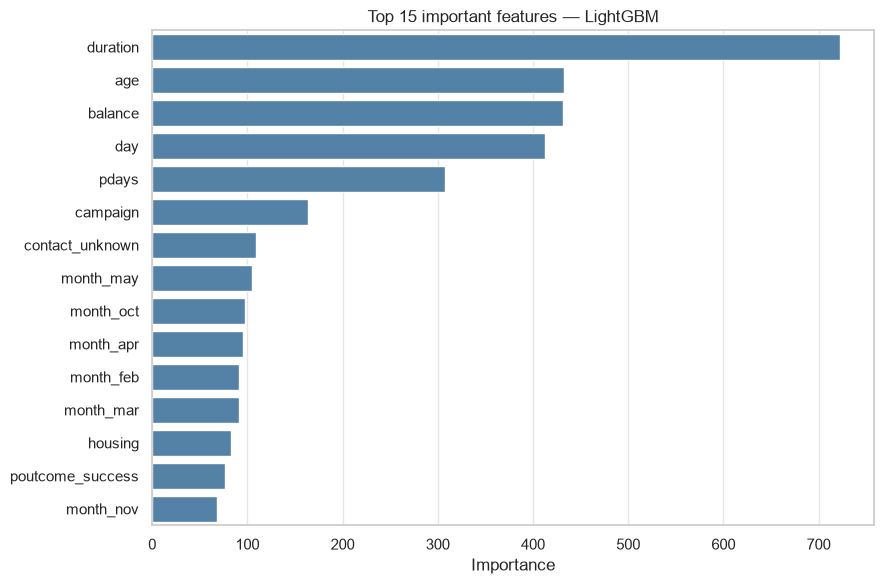

In [21]:
tree_names = [n for n in results["Model"]
              if hasattr(fitted[n].named_steps["model"], "feature_importances_")]
best_tree = tree_names[0]
print(best_tree)

feat_names = fitted[best_tree].named_steps["prep"].get_feature_names_out()
imp = pd.Series(fitted[best_tree].named_steps["model"].feature_importances_, index=feat_names)
imp = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=[n.split("__")[-1] for n in imp.index], color="steelblue")
plt.title(f"Top 15 important features — {best_tree}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [22]:
def eval_gb(drop_duration):
    Xtr, Xte = X_train.copy(), X_test.copy()
    if drop_duration:
        Xtr = Xtr.drop(columns="duration", errors="ignore")
        Xte = Xte.drop(columns="duration", errors="ignore")
    pipe = Pipeline([("prep", make_preprocessor(Xtr)),
                     ("model", GradientBoostingClassifier(n_estimators=200, random_state=RANDOM_STATE))])
    pipe.fit(Xtr, y_train)
    return (accuracy_score(y_test, pipe.predict(Xte)),
            roc_auc_score(y_test, pipe.predict_proba(Xte)[:, 1]))

dur = pd.DataFrame({
    "Setup": ["مع duration", "من غير duration"],
    "Test Accuracy": [eval_gb(False)[0], eval_gb(True)[0]],
    "ROC-AUC":       [eval_gb(False)[1], eval_gb(True)[1]],
}).round(4)
dur

,Setup,Test Accuracy,ROC-AUC
0,مع duration,0.8501,0.9135
1,من غير duration,0.7316,0.7833


In [23]:
param_dist = {
    "model__n_estimators":     [100, 200, 300],
    "model__learning_rate":    [0.03, 0.05, 0.1],
    "model__max_depth":        [2, 3, 4, 5],
    "model__subsample":        [0.7, 0.85, 1.0],
    "model__min_samples_leaf": [1, 5, 10],
}

gb_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))])

search = RandomizedSearchCV(gb_pipe, param_dist, n_iter=10, cv=3, scoring="accuracy",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print( search.best_params_)

tuned_pred  = search.predict(X_test)
tuned_proba = search.predict_proba(X_test)[:, 1]
base = results[results["Model"] == "Gradient Boosting"].iloc[0]

pd.DataFrame({
    "Model": ["Gradient Boosting (default)", "Gradient Boosting (tuned)"],
    "Test Accuracy": [base["Test Accuracy"], accuracy_score(y_test, tuned_pred)],
    "ROC-AUC":       [base["ROC-AUC"], roc_auc_score(y_test, tuned_proba)],
}).round(4)

{'model__subsample': 0.85, 'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__learning_rate': 0.05}


,Model,Test Accuracy,ROC-AUC
0,Gradient Boosting (default),0.8490,0.9167
1,Gradient Boosting (tuned),0.8551,0.9183


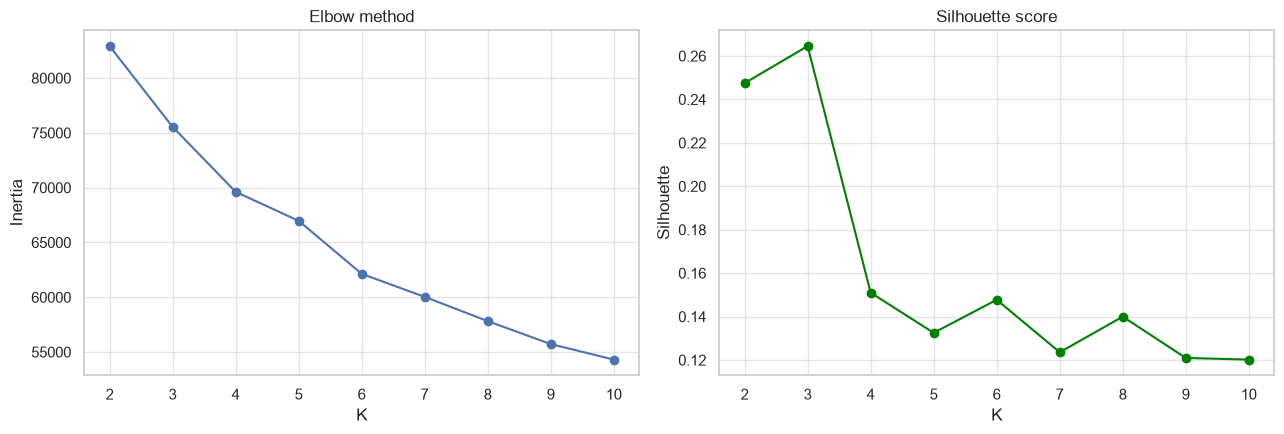

أعلى Silhouette عند K = 3


In [24]:
prep_km = clone(preprocessor)
Xk = prep_km.fit_transform(X_train)

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xk)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xk, km.labels_, sample_size=2000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Elbow method")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(ks), sils, "o-", color="green"); axes[1].set_title("Silhouette score")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

best_k = list(ks)[int(np.argmax(sils))]
print("أعلى Silhouette عند K =", best_k)

In [25]:
print("=" * 64)
r = results.loc[0]
print(f"أفضل موديل (ROC-AUC): {r['Model']}")
print(f"Accuracy = {r['Test Accuracy']:.4f} | Precision = {r['Precision']:.4f} | Recall = {r['Recall']:.4f} | F1 = {r['F1']:.4f} | AUC = {r['ROC-AUC']:.4f}")
print("=" * 64)
print("\nالترتيب:")
for i, r in results.iterrows():
    print(f"{i+1:>2}. {r['Model']:<22} Acc = {r['Test Accuracy']:.4f}   AUC = {r['ROC-AUC']:.4f}")

أفضل موديل (ROC-AUC): HistGradientBoosting
Accuracy = 0.8551 | Precision = 0.8210 | Recall = 0.8889 | F1 = 0.8536 | AUC = 0.9204

الترتيب:
 1. HistGradientBoosting   Acc = 0.8551   AUC = 0.9204
 2. LightGBM               Acc = 0.8535   AUC = 0.9187
 3. XGBoost                Acc = 0.8557   AUC = 0.9175
 4. Gradient Boosting      Acc = 0.8490   AUC = 0.9167
 5. Random Forest          Acc = 0.8506   AUC = 0.9099
 6. SVC (RBF)              Acc = 0.8467   AUC = 0.9081
 7. Neural Network (MLP)   Acc = 0.8405   AUC = 0.9077
 8. Logistic Regression    Acc = 0.8237   AUC = 0.8949
 9. Extra Trees            Acc = 0.8209   AUC = 0.8910
10. AdaBoost               Acc = 0.8214   AUC = 0.8890
11. KNN                    Acc = 0.8119   AUC = 0.8769
12. Decision Tree          Acc = 0.8113   AUC = 0.8586
13. Naive Bayes            Acc = 0.6816   AUC = 0.7696
